# EGMS — analiza budynków w Łęcznej

Przypisuje najbliższy punkt EGMS do budynku, pokazuje statystyki i zapisuje jeden wynikowy слой z oryginalnymi atrybutami oraz polami EGMS.

## 1. Ustawienia

In [17]:
from pathlib import Path
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt

PS_CSV = "output/EGMS_Leczna_results.csv"
BUILDINGS_FILE = "data/PL_81_Leczna/PL_81_Leczna.shp"
OUTPUT_GPKG = "output/budynki_EGMS_Leczna_results.gpkg"
MAX_DISTANCE_M = 30
PS_CRS = "EPSG:3035"


## 2. Wczytanie i kontrola danych

In [18]:
for file_name in [PS_CSV, BUILDINGS_FILE]:
    if not Path(file_name).exists():
        raise FileNotFoundError(f"Nie znaleziono pliku: {file_name}")

ps = pd.read_csv(PS_CSV)
buildings = gpd.read_file(BUILDINGS_FILE)

required = ["pid", "easting", "northing", "mean_velocity", "anomaly_score", "anomaly", "cluster"]
missing = [col for col in required if col not in ps.columns]
if missing:
    raise ValueError(f"Brak kolumn w CSV: {missing}")
if buildings.empty:
    raise ValueError("Warstwa budynków jest pusta.")
if buildings.crs is None:
    raise ValueError("Warstwa budynków nie ma zdefiniowanego CRS.")

buildings = buildings.loc[
    buildings.geometry.notna() & ~buildings.geometry.is_empty
].drop_duplicates(subset="geometry").copy().reset_index(drop=True)
buildings["EGMS_building_id"] = np.arange(1, len(buildings) + 1)

for col in ["easting", "northing", "mean_velocity", "anomaly_score", "cluster"]:
    ps[col] = pd.to_numeric(ps[col], errors="coerce")

def to_bool(value):
    if pd.isna(value):
        return pd.NA
    if isinstance(value, (bool, np.bool_)):
        return bool(value)
    value = str(value).strip().lower()
    if value in {"true", "1", "yes", "tak"}:
        return True
    if value in {"false", "0", "no", "nie"}:
        return False
    return pd.NA

ps["anomaly"] = ps["anomaly"].map(to_bool).astype("boolean")
ps = ps.dropna(subset=["easting", "northing"]).copy()

points = gpd.GeoDataFrame(
    ps, geometry=gpd.points_from_xy(ps["easting"], ps["northing"]), crs=PS_CRS
)
buildings = buildings.to_crs(PS_CRS)

print(f"Punkty EGMS: {len(points)}")
print(f"Budynki: {len(buildings)}")
print(f"CRS budynków po transformacji: {buildings.crs}")
print(f"Punkty oznaczone jako anomalne: {int(points['anomaly'].fillna(False).sum())}")


Punkty EGMS: 2405
Budynki: 10545
CRS budynków po transformacji: EPSG:3035
Punkty oznaczone jako anomalne: 121


## 3. Przypisanie punktów do budynków

In [19]:
if MAX_DISTANCE_M <= 0:
    raise ValueError("MAX_DISTANCE_M musi być większe od zera.")

joined = gpd.sjoin_nearest(
    buildings[["EGMS_building_id", "geometry"]],
    points[["pid", "mean_velocity", "anomaly_score", "anomaly", "cluster", "geometry"]],
    how="left",
    max_distance=MAX_DISTANCE_M,
    distance_col="EGMS_distance_m"
)

joined = (
    joined.reset_index(drop=True)
    .sort_values(
        ["EGMS_building_id", "EGMS_distance_m", "anomaly_score", "pid"],
        ascending=[True, True, False, True],
        na_position="last"
    )
    .drop_duplicates("EGMS_building_id")
)

joined["EGMS_has_PS"] = joined["pid"].notna()
joined["EGMS_has_anomaly"] = (
    joined["EGMS_has_PS"] & joined["anomaly"].fillna(False).astype(bool)
)
joined = joined.rename(columns={
    "pid": "EGMS_pid",
    "mean_velocity": "EGMS_mean_velocity",
    "anomaly_score": "EGMS_anomaly_score",
    "anomaly": "EGMS_anomaly",
    "cluster": "EGMS_cluster"
})

attributes = joined.drop(columns=["geometry", "index_right"], errors="ignore")
result = gpd.GeoDataFrame(
    buildings.merge(attributes, on="EGMS_building_id", how="left"),
    geometry="geometry", crs=buildings.crs
)
matched = result["EGMS_has_PS"].fillna(False)
anomalous = result["EGMS_has_anomaly"].fillna(False)

print(f"Budynki z punktem PS do {MAX_DISTANCE_M} m: {int(matched.sum())} ({matched.mean()*100:.1f}%)")
print(f"Budynki bez przypisanego punktu: {int((~matched).sum())}")
print(f"Budynki przypisane do anomalii: {int(anomalous.sum())}")
print(f"Unikalne przypisane punkty PID: {result.loc[matched, 'EGMS_pid'].nunique()}")
if matched.any():
    print(f"Mediana odległości: {result.loc[matched, 'EGMS_distance_m'].median():.2f} m")
    print(f"95. percentyl odległości: {result.loc[matched, 'EGMS_distance_m'].quantile(0.95):.2f} m")


Budynki z punktem PS do 30 m: 4212 (39.9%)
Budynki bez przypisanego punktu: 6333
Budynki przypisane do anomalii: 84
Unikalne przypisane punkty PID: 1388
Mediana odległości: 18.78 m
95. percentyl odległości: 29.03 m


## 4. Histogram i pokrycie budynków

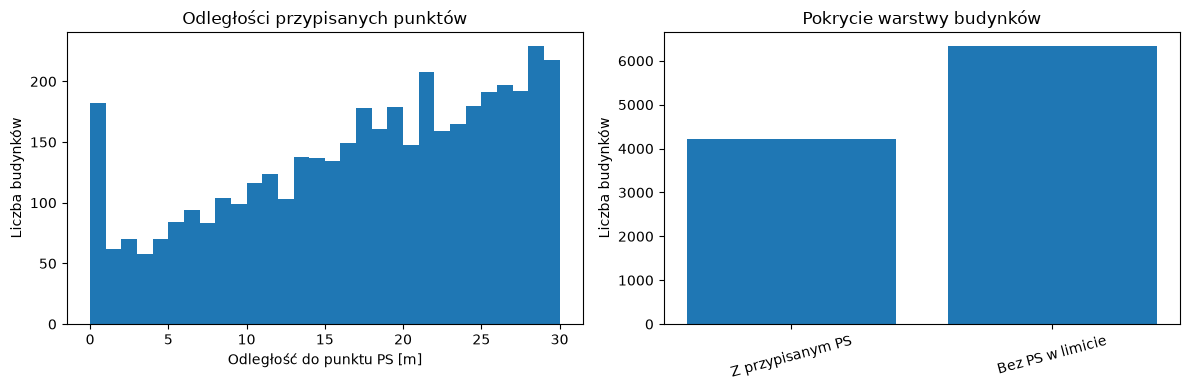

In [20]:
distances = result.loc[matched, "EGMS_distance_m"].dropna()
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

if len(distances):
    axes[0].hist(distances, bins=30)
    axes[0].set_xlabel("Odległość do punktu PS [m]")
    axes[0].set_ylabel("Liczba budynków")
    axes[0].set_title("Odległości przypisanych punktów")
else:
    axes[0].text(0.5, 0.5, "Brak dopasowanych budynków", ha="center", va="center")
    axes[0].set_axis_off()

coverage = pd.Series({
    "Z przypisanym PS": int(matched.sum()),
    "Bez PS w limicie": int((~matched).sum())
})
axes[1].bar(coverage.index, coverage.values)
axes[1].set_ylabel("Liczba budynków")
axes[1].set_title("Pokrycie warstwy budynków")
axes[1].tick_params(axis="x", rotation=15)

plt.tight_layout()
plt.show()


## 5. Mapa budynków według klastrów

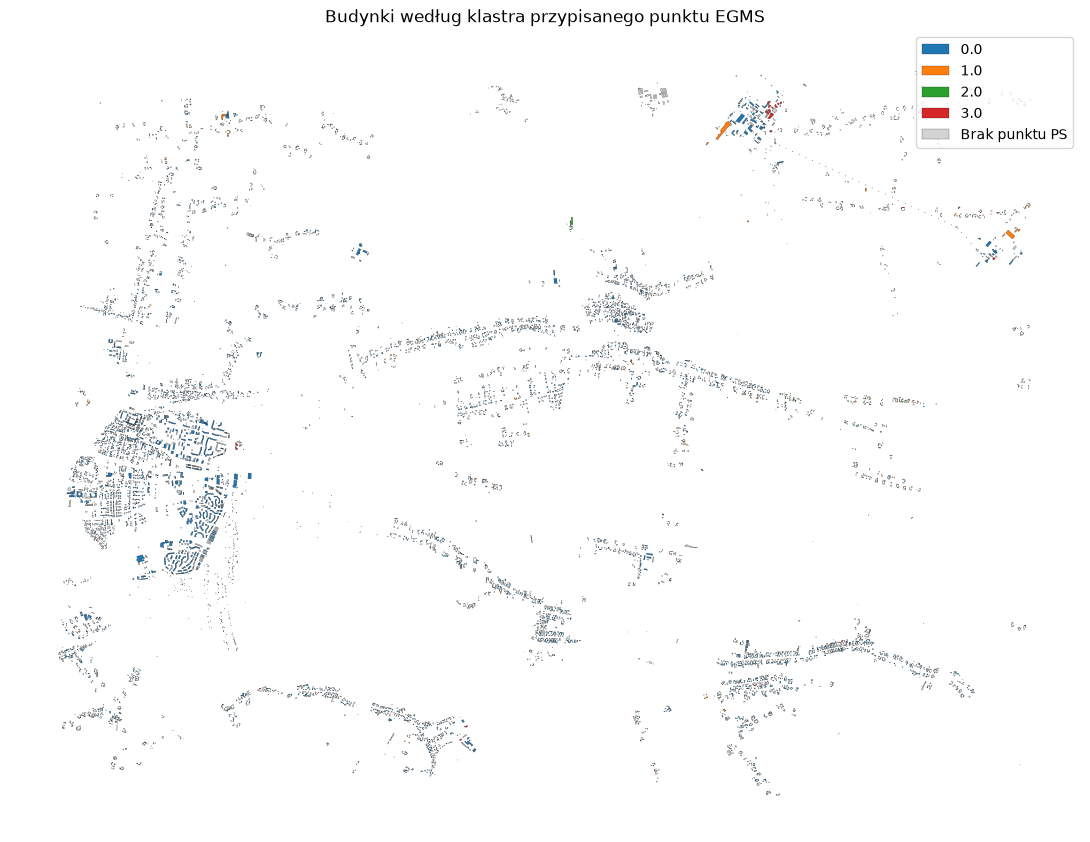

In [21]:
fig, ax = plt.subplots(figsize=(11, 9))
result.plot(
    column="EGMS_cluster",
    categorical=True,
    legend=True,
    cmap="tab10",
    missing_kwds={"color": "lightgrey", "label": "Brak punktu PS"},
    linewidth=0.15,
    edgecolor="black",
    ax=ax
)
ax.set_title("Budynki według klastra przypisanego punktu EGMS")
ax.set_axis_off()
plt.tight_layout()
plt.show()


## 6. Tabele statystyczne

In [22]:
summary = pd.DataFrame({
    "Wskaźnik": [
        "Liczba budynków",
        "Budynki z przypisanym punktem PS",
        "Budynki bez punktu PS w limicie",
        "Budynki przypisane do anomalii",
        "Pokrycie warstwy budynków [%]",
        "Unikalne przypisane punkty EGMS"
    ],
    "Wartość": [
        len(result),
        int(matched.sum()),
        int((~matched).sum()),
        int(anomalous.sum()),
        round(100 * matched.mean(), 1) if len(result) else 0,
        int(result.loc[matched, "EGMS_pid"].nunique())
    ]
})
display(summary)

cluster_summary = (
    result.loc[matched]
    .groupby("EGMS_cluster", dropna=False)
    .agg(
        buildings=("EGMS_building_id", "count"),
        buildings_with_anomaly=("EGMS_has_anomaly", "sum"),
        median_distance_m=("EGMS_distance_m", "median"),
        median_mean_velocity=("EGMS_mean_velocity", "median"),
        median_anomaly_score=("EGMS_anomaly_score", "median")
    )
    .round(3)
    .sort_index()
)
cluster_summary


,Wskaźnik,Wartość
0,Liczba budynków,10545.0
1,Budynki z przypisanym punktem PS,4212.0
2,Budynki bez punktu PS w limicie,6333.0
3,Budynki przypisane do anomalii,84.0
4,Pokrycie warstwy budynków [%],39.9
5,Unikalne przypisane punkty EGMS,1388.0


,buildings,buildings_with_anomaly,median_distance_m,median_mean_velocity,median_anomaly_score
EGMS_cluster,,,,,
0.0,3829,0,18.770,0.30,0.344
1.0,194,34,19.098,0.65,0.456
2.0,71,34,18.361,5.10,0.580
3.0,118,16,18.805,-1.30,0.467


## 7. Zapis jednej warstwy

In [23]:
output_path = Path(OUTPUT_GPKG)
output_path.parent.mkdir(parents=True, exist_ok=True)
if output_path.exists():
    output_path.unlink()

result.to_file(OUTPUT_GPKG, layer="PL_81_Leczna_EGMS", driver="GPKG")
print(f"Zapisano: {OUTPUT_GPKG}")
print("Warstwa: PL_81_Leczna_EGMS")
print(f"Liczba budynków w wyniku: {len(result)}")


Zapisano: output/budynki_EGMS_Leczna_results.gpkg
Warstwa: PL_81_Leczna_EGMS
Liczba budynków w wyniku: 10545


## Interpretacja i ograniczenia

- `EGMS_cluster` to klaster przypisanej najbliższej punktowi PS, nie niezależna klasyfikacja konstrukcji budynku.
- `EGMS_anomaly` i `EGMS_anomaly_score` opisują punkt EGMS.
- Budynek bez punktu w przyjętym promieniu pozostaje bez przypisanych wyników.
- Bliska odległość punktu od budynku nie dowodzi, że pomiar opisuje deformację samego budynku.
- Grupy pól w formularzu identyfikacji QGIS konfiguruje się w projekcie QGIS; prefiks `EGMS_` sam nie tworzy rozwijanej grupy.